In [34]:
import tifffile as tff
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

default_file_path = "../../data/raw/"
save_file_path = "../../data/iterim/"

In [35]:
permeability = tff.imread(f"{default_file_path}permeability.tif")
wells_df = pd.read_parquet(f"{save_file_path}wells.parquet")

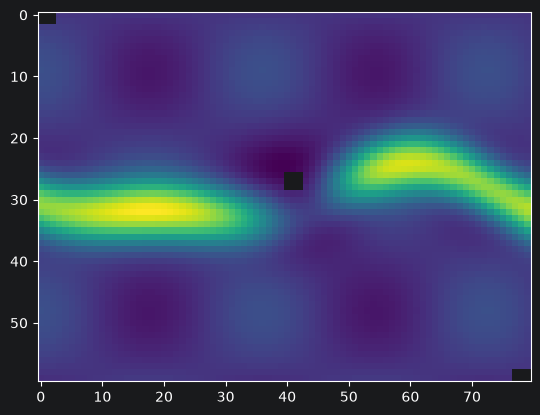

In [36]:
permeability[permeability.round(0) == -9999] = np.nan

plt.imshow(permeability, cmap="viridis")

In [37]:
wells_df[["x", "y"]]

,x,y
1,2199.55,255.93
2,3476.6,2001.54
3,2044.9,1235.17
4,2447.4,1551.83
5,3827.05,1397.65
...,...,...
323,3673.47,1638.95
324,403.67,1888.58
325,2573.18,1254.71
326,1419.3,1321.91


In [38]:
print(*permeability)

[      nan       nan       nan 25.344915 25.299019 25.244255 25.182247
 25.114836 25.04402  24.971899 24.90061  24.83227  24.768902 24.712387
 24.6644   24.626366 24.599411 24.584333 24.581583 24.59124  24.613016
 24.646269 24.690012 24.742945 24.803501 24.869883 24.940125 25.01214
 25.083796 25.152966 25.2176   25.275782 25.325785 25.366125 25.395609
 25.413363 25.418856 25.41193  25.392786 25.361998 25.320473 25.269444
 25.210426 25.145168 25.075605 25.0038   24.93188  24.861982 24.796175
 24.736412 24.684464 24.641872 24.6099   24.589493 24.581259 24.58544
 24.601915 24.630194 24.669437 24.718483 24.775875 24.839914 24.9087
 24.980194 25.052275 25.122805 25.189693 25.250957 25.30478  25.349564
 25.383982 25.407015 25.417978 25.416548 25.402765 25.377039 25.340134
 25.29314  25.237455 25.17473 ] [      nan       nan       nan 26.025793 25.889294 25.726423 25.542011
 25.341528 25.130917 24.916424 24.70441  24.50116  24.312702 24.144627
 24.001913 23.888798 23.80863  23.763792 23.75561

In [39]:
row = (wells_df["y"] // 50).to_numpy(dtype=int)
columns = (wells_df["x"] // 50).to_numpy(dtype=int)

wells_df["permeability"] = permeability[row, columns].astype("float64").round(2)

In [42]:
display(wells_df)
display(wells_df.dtypes)

,well_id,x,y,z,role,zone,commissioned,permeability
1,BH-271,2199.55,255.93,-11.41,monitoring,central_zone,2018-10-29,26.40
2,BH-243,3476.6,2001.54,-10.85,monitoring,water_intake_zone,2018-10-01,26.08
3,BH-166,2044.9,1235.17,-20.01,monitoring,central_zone,2018-07-16,16.34
4,BH-167,2447.4,1551.83,-48.09,monitoring,central_zone,2018-07-17,33.44
5,BH-257,3827.05,1397.65,-40.28,monitoring,water_intake_zone,2018-10-15,51.96
...,...,...,...,...,...,...,...,...
323,BH-233,3673.47,1638.95,-8.14,monitoring,water_intake_zone,2018-09-21,44.28
324,BH-024,403.67,1888.58,-21.57,monitoring,industrial_zone,2018-02-24,40.08
325,BH-139,2573.18,1254.71,-28.88,monitoring,central_zone,2018-06-19,53.43
326,BH-025,1419.3,1321.91,-50.37,monitoring,central_zone,2018-02-25,30.32


well_id                    str
x                      Float64
y                      Float64
z                      Float64
role                       str
zone                       str
commissioned    datetime64[us]
permeability           float64
dtype: object

In [41]:
wells_df.to_parquet(f"{save_file_path}wells.parquet", engine="pyarrow")